# EfficientNet-B3 Image + Metadata Late Fusion — Final Unified Experiment

Binary classification of dermoscopic skin-lesion images from the existing merged, deduplicated,
lesion-grouped HAM10000 + ISIC Extra split. Labels are **0 = Benign** and **1 = Malignant**.

This notebook preserves the original image-only pipeline through validation-based experiment selection,
including its split files, image transforms, loss, samplers, calibration, threshold objective, and
McNemar-based comparison. It then adds one controlled late-fusion experiment using `age`, `sex`, and
`localization`. Metadata preprocessing is fitted on training data only. The final section evaluates the
selected image-only model and the multimodal candidate on the untouched test set for direct comparison.
The production checkpoint is never overwritten automatically; promotion is an explicit, opt-in function.

## 1. Imports and reproducibility

In [2]:
import json
import logging
import math
import random
import warnings
from datetime import datetime
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import log_loss
import shutil
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M%S')

logger = logging.getLogger('Binary_EfficientNetB3_Baseline_V2_Experiments')
logger.setLevel(logging.INFO)
logger.handlers.clear()
handler = logging.StreamHandler()
handler.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
logger.addHandler(handler)

## 2. Configuration and unchanged project paths

The paths below are the same paths used by the original notebook. The original split files are
loaded without re-splitting, and the test split is retained only for the final evaluation cell.

In [3]:
def find_project_root(start: Path, markers=('Data', 'notebooks')) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(
        f'Could not find a project root containing {markers} above {start}. '
        'Run this notebook from the project root or its notebooks directory.'
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / 'Data' / 'datasets' / 'HAM10000_ISICExtra_binary'
METADATA_DIR = DATASET_DIR / 'metadata'
IMAGES_DIR = DATASET_DIR / 'images'

OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'binary' / 'Binary_EfficientNetB3_Baseline_V2'
CHECKPOINTS_DIR = OUTPUT_DIR / 'checkpoints'
PREDICTIONS_DIR = OUTPUT_DIR / 'predictions'
PLOTS_DIR = OUTPUT_DIR / 'plots'
TRAINING_CURVES_DIR = PLOTS_DIR / 'training_curves'
ROC_PR_DIR = PLOTS_DIR / 'roc_pr_curves'
CONFUSION_MATRICES_DIR = PLOTS_DIR / 'confusion_matrices'
CALIBRATION_DIR = PLOTS_DIR / 'calibration'

for directory in [
    OUTPUT_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR, PLOTS_DIR,
    TRAINING_CURVES_DIR, ROC_PR_DIR, CONFUSION_MATRICES_DIR, CALIBRATION_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'batch_size': 32,
    'num_workers': 0,
    'epochs': 20,
    'early_stopping_patience': 5,
    'grad_clip_norm': 1.0,
    'use_amp': torch.cuda.is_available(),
    'cb_beta': 0.9999,
    'focal_gamma': 2.0,
    'use_tta': True,
    'img_size': 300,
    'backbone_lr': 1e-4,
    'head_lr': 1e-3,
    'weight_decay': 1e-4,
    'warmup_freeze_epochs': 2,
}

logger.info('PROJECT_ROOT: %s', PROJECT_ROOT)
logger.info('DATASET_DIR: %s', DATASET_DIR)
logger.info('OUTPUT_DIR: %s', OUTPUT_DIR)
logger.info('DEVICE: %s', DEVICE)

2026-08-22 20:42:26,643 | INFO | PROJECT_ROOT: D:\SkinCancer_Project
2026-08-22 20:42:26,643 | INFO | DATASET_DIR: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary
2026-08-22 20:42:26,643 | INFO | OUTPUT_DIR: D:\SkinCancer_Project\outputs\binary\Binary_EfficientNetB3_Baseline_V2
2026-08-22 20:42:26,643 | INFO | DEVICE: cuda


## 3. Dataset validation and immutable split loading

In [4]:
BINARY_LABEL_MAP = {'mel': 1, 'bcc': 1, 'akiec': 1, 'nv': 0, 'bkl': 0, 'df': 0, 'vasc': 0}
BINARY_LABEL_NAMES = {0: 'Benign', 1: 'Malignant'}

def verify_dataset(metadata_dir: Path, images_dir: Path) -> None:
    required_files = ['train.csv', 'val.csv', 'test.csv']
    required_columns = {'image_id', 'image_path'}
    missing = [name for name in required_files if not (metadata_dir / name).exists()]
    if missing:
        raise FileNotFoundError(f'Missing expected metadata file(s): {missing}')
    missing_dirs = [name for name in ['train', 'val', 'test'] if not (images_dir / name).exists()]
    if missing_dirs:
        raise FileNotFoundError(f'Missing expected image split folder(s): {missing_dirs}')
    for filename in required_files:
        columns = set(pd.read_csv(metadata_dir / filename, nrows=1).columns)
        missing_columns = required_columns - columns
        if missing_columns:
            raise ValueError(f'{filename} is missing required column(s): {missing_columns}')

def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    result = df.copy()
    split_dir = images_dir / split_name

    def resolve(raw_path: str) -> str:
        current_path = Path(str(raw_path))
        if current_path.parent == split_dir:
            return str(current_path)
        return str(split_dir / current_path.name)

    result['image_path'] = result['image_path'].map(resolve)
    return result

def prepare_binary_labels(df: pd.DataFrame, name: str) -> pd.DataFrame:
    result = df.copy()
    if 'binary_label' not in result.columns:
        if 'dx' not in result.columns:
            raise ValueError(f'{name}: neither binary_label nor dx is available.')
        result['binary_label'] = result['dx'].map(BINARY_LABEL_MAP)
    if result['binary_label'].isna().any():
        raise ValueError(f'{name}: missing or unmapped binary labels found.')
    result['binary_label'] = result['binary_label'].astype(int)
    if set(result['binary_label'].unique()) != {0, 1}:
        raise ValueError(f'{name}: expected exactly labels {{0, 1}}.')
    return result

verify_dataset(METADATA_DIR, IMAGES_DIR)
train_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'train.csv'), IMAGES_DIR, 'train'), 'train'
)
val_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'val.csv'), IMAGES_DIR, 'val'), 'val'
)
test_df = prepare_binary_labels(
    resolve_processed_image_paths(pd.read_csv(METADATA_DIR / 'test.csv'), IMAGES_DIR, 'test'), 'test'
)

id_sets = {
    'train': set(train_df['image_id']),
    'val': set(val_df['image_id']),
    'test': set(test_df['image_id']),
}
overlaps = {
    'train_val': id_sets['train'] & id_sets['val'],
    'train_test': id_sets['train'] & id_sets['test'],
    'val_test': id_sets['val'] & id_sets['test'],
}
if sum(len(ids) for ids in overlaps.values()) > 0:
    raise RuntimeError({name: len(ids) for name, ids in overlaps.items()})
duplicated_splits = [
    name for name, frame in [('train', train_df), ('val', val_df), ('test', test_df)]
    if frame['image_id'].duplicated().any()
]
if duplicated_splits:
    raise RuntimeError(f'Duplicate image_id values found in split(s): {duplicated_splits}.')

if all('lesion_id' in frame.columns for frame in [train_df, val_df, test_df]):
    lesion_groups = {
        name: set(frame['lesion_id'].dropna().astype(str))
        for name, frame in [('train', train_df), ('val', val_df), ('test', test_df)]
    }
    lesion_overlaps = {
        f'{left}_{right}': lesion_groups[left] & lesion_groups[right]
        for left, right in [('train', 'val'), ('train', 'test'), ('val', 'test')]
    }
    if any(lesion_overlaps.values()):
        raise RuntimeError({name: len(groups) for name, groups in lesion_overlaps.items() if groups})
    logger.info('lesion_id group integrity verified: no group spans train, validation, and test.')
elif any('lesion_id' in frame.columns for frame in [train_df, val_df, test_df]):
    logger.warning('lesion_id is present in only some splits; group-disjointness audit is partial.')
logger.info(
    'Splits loaded: train=%d, val=%d, test=%d; test remains untouched until the final cell.',
    len(train_df), len(val_df), len(test_df)
)

2026-08-22 20:42:26,899 | INFO | lesion_id group integrity verified: no group spans train, validation, and test.
2026-08-22 20:42:26,899 | INFO | Splits loaded: train=8587, val=2147, test=2147; test remains untouched until the final cell.


## 4. EfficientNet-B3 model, transforms, and data loaders

These are unchanged from the original notebook: ImageNet1K_V1 preprocessing, 320px resize to a
300px crop, the same training augmentation, and the same three-view TTA (identity, horizontal
flip, vertical flip).

In [5]:
class SkinLesionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row['image_path']) as image:
            image = image.convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        return image, label, row['image_id']

class EfficientNetB3BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = torchvision.models.EfficientNet_B3_Weights.IMAGENET1K_V1
        self.backbone = torchvision.models.efficientnet_b3(weights=self.weights)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_features, 1))
        self.freeze_backbone()

    def forward(self, x):
        return self.backbone(x).squeeze(1)

    def freeze_backbone(self):
        for name, parameter in self.backbone.named_parameters():
            if 'classifier' not in name:
                parameter.requires_grad = False

    def unfreeze_backbone(self):
        for name, parameter in self.backbone.named_parameters():
            if 'classifier' not in name:
                parameter.requires_grad = True

    def backbone_trainable_parameters(self):
        return [
            parameter for name, parameter in self.backbone.named_parameters()
            if 'classifier' not in name and parameter.requires_grad
        ]

    def head_parameters(self):
        return list(self.backbone.classifier.parameters())

preprocessing_model = EfficientNetB3BinaryClassifier()
transform_meta = preprocessing_model.weights.transforms()
CONFIG['resize_size'] = transform_meta.resize_size[0]
CONFIG['img_size'] = transform_meta.crop_size[0]
CONFIG['norm_mean'] = list(transform_meta.mean)
CONFIG['norm_std'] = list(transform_meta.std)
CONFIG['interpolation'] = 'bicubic'
del preprocessing_model

interpolation = InterpolationMode.BICUBIC
train_transform = transforms.Compose([
    transforms.Resize(CONFIG['resize_size'], interpolation=interpolation),
    transforms.RandomCrop(CONFIG['img_size']),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG['norm_mean'], std=CONFIG['norm_std']),
])

def build_eval_transform(hflip=False, vflip=False):
    ops = []
    if hflip:
        ops.append(transforms.RandomHorizontalFlip(p=1.0))
    if vflip:
        ops.append(transforms.RandomVerticalFlip(p=1.0))
    ops.extend([
        transforms.Resize(CONFIG['resize_size'], interpolation=interpolation),
        transforms.CenterCrop(CONFIG['img_size']),
        transforms.ToTensor(),
        transforms.Normalize(mean=CONFIG['norm_mean'], std=CONFIG['norm_std']),
    ])
    return transforms.Compose(ops)

eval_transform = build_eval_transform()
tta_transforms = [
    eval_transform,
    build_eval_transform(hflip=True),
    build_eval_transform(vflip=True),
]

train_dataset = SkinLesionDataset(train_df, train_transform)
val_dataset = SkinLesionDataset(val_df, eval_transform)
test_dataset = SkinLesionDataset(test_df, eval_transform)
train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'], shuffle=True,
    num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)

## 5. Unchanged loss and inference utilities

In [6]:
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta=0.9999, gamma=2.0, device='cpu'):
        super().__init__()
        samples_per_class = np.asarray(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)
        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
        self.gamma = gamma

    def forward(self, logits, targets):
        alpha_t = targets * self.class_weights[1] + (1.0 - targets) * self.class_weights[0]
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probabilities = torch.sigmoid(logits)
        p_t = probabilities * targets + (1.0 - probabilities) * (1.0 - targets)
        return (alpha_t * (1.0 - p_t).pow(self.gamma) * bce_loss).mean()

@torch.no_grad()
def collect_probs_tta(model, df, transform_list):
    model.eval()
    view_probabilities = []
    labels_reference = None
    ids_reference = None
    for transform in transform_list:
        dataset = SkinLesionDataset(df, transform)
        loader = DataLoader(
            dataset, batch_size=CONFIG['batch_size'], shuffle=False,
            num_workers=CONFIG['num_workers'], pin_memory=True
        )
        probabilities, labels, ids = [], [], []
        for images, batch_labels, batch_ids in tqdm(loader, desc='TTA view', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with autocast(enabled=CONFIG['use_amp']):
                logits = model(images)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(batch_ids)
        view_probabilities.append(np.concatenate(probabilities))
        if labels_reference is None:
            labels_reference = np.concatenate(labels).astype(int)
            ids_reference = ids
    return np.mean(view_probabilities, axis=0), labels_reference, ids_reference

@torch.no_grad()
def collect_probs_single(model, loader):
    model.eval()
    probabilities, labels, ids = [], [], []
    with torch.no_grad():
        for images, batch_labels, batch_ids in tqdm(loader, desc='inference', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with autocast(enabled=CONFIG['use_amp']):
                logits = model(images)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(batch_ids)
    return np.concatenate(probabilities), np.concatenate(labels).astype(int), ids

def fit_platt_calibrator(raw_probabilities, labels):
    calibrator = LogisticRegression(C=1e10, solver='lbfgs')
    calibrator.fit(raw_probabilities.reshape(-1, 1), labels.astype(int))
    return calibrator

def calibrated_probabilities(calibrator, raw_probabilities):
    return calibrator.predict_proba(raw_probabilities.reshape(-1, 1))[:, 1]

## 6. Baseline checkpoint reproduction (validation only)

The existing `best_model.pth` is loaded as the baseline. This cell performs inference on the
validation split only, with the original TTA and Platt calibration procedure. The checkpoint's
stored threshold is used for the baseline row; no threshold is selected using test data.

In [7]:
def load_checkpoint(path: Path):
    if not path.exists():
        raise FileNotFoundError(
            f'Original checkpoint not found at {path}. The notebook must be run in the same project '
            'where the original outputs were created.'
        )
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')

original_checkpoint_path = CHECKPOINTS_DIR / 'best_model.pth'
original_checkpoint = load_checkpoint(original_checkpoint_path)
baseline_model = EfficientNetB3BinaryClassifier().to(DEVICE)
baseline_model.load_state_dict(original_checkpoint['model_state'])
baseline_model.eval()

if CONFIG['use_tta']:
    baseline_val_raw, val_labels, val_ids = collect_probs_tta(baseline_model, val_df, tta_transforms)
else:
    baseline_val_raw, val_labels, val_ids = collect_probs_single(baseline_model, val_loader)
baseline_calibrator = fit_platt_calibrator(baseline_val_raw, val_labels)
baseline_val_probs = calibrated_probabilities(baseline_calibrator, baseline_val_raw)

baseline_threshold = float(original_checkpoint.get('best_threshold', 0.39))
baseline_checkpoint_info = {
    'best_epoch': original_checkpoint.get('best_epoch'),
    'best_val_auc': original_checkpoint.get('best_val_auc'),
    'threshold': baseline_threshold,
}
logger.info('Baseline checkpoint metadata: %s', baseline_checkpoint_info)

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 20:44:07,875 | INFO | Baseline checkpoint metadata: {'best_epoch': 19, 'best_val_auc': 0.9432319692903846, 'threshold': 0.33}


## 7. Experiment 1 — Threshold re-optimization on validation only

The threshold grid is exactly 0.05 through 0.95 in increments of 0.005. Every grid point records
Balanced Accuracy, malignant F1, macro F1, malignant Recall, malignant Precision, Specificity, and
Youden's J. Four candidates are reported: F1-optimal, Balanced-Accuracy-optimal, Youden-J-optimal,
and the constrained candidate maximizing Balanced Accuracy while Recall remains at least **0.8279**.

**Selection rule (updated)**: the selected threshold is the candidate maximizing
`mean(Balanced Accuracy, Malignant F1)` - the project's two confirmed primary objectives. Micro F1
was considered as a second objective and explicitly rejected: for binary classification, Micro F1
is mathematically identical to Accuracy (verified: both equal `(TP+TN)/N`), so it cannot serve as
a meaningful second axis alongside Balanced Accuracy - it would silently reduce this to
Accuracy-only selection, which the project's own methodology rules elsewhere prohibit. Recall,
Precision, Specificity, and Macro F1 remain fully reported for context.

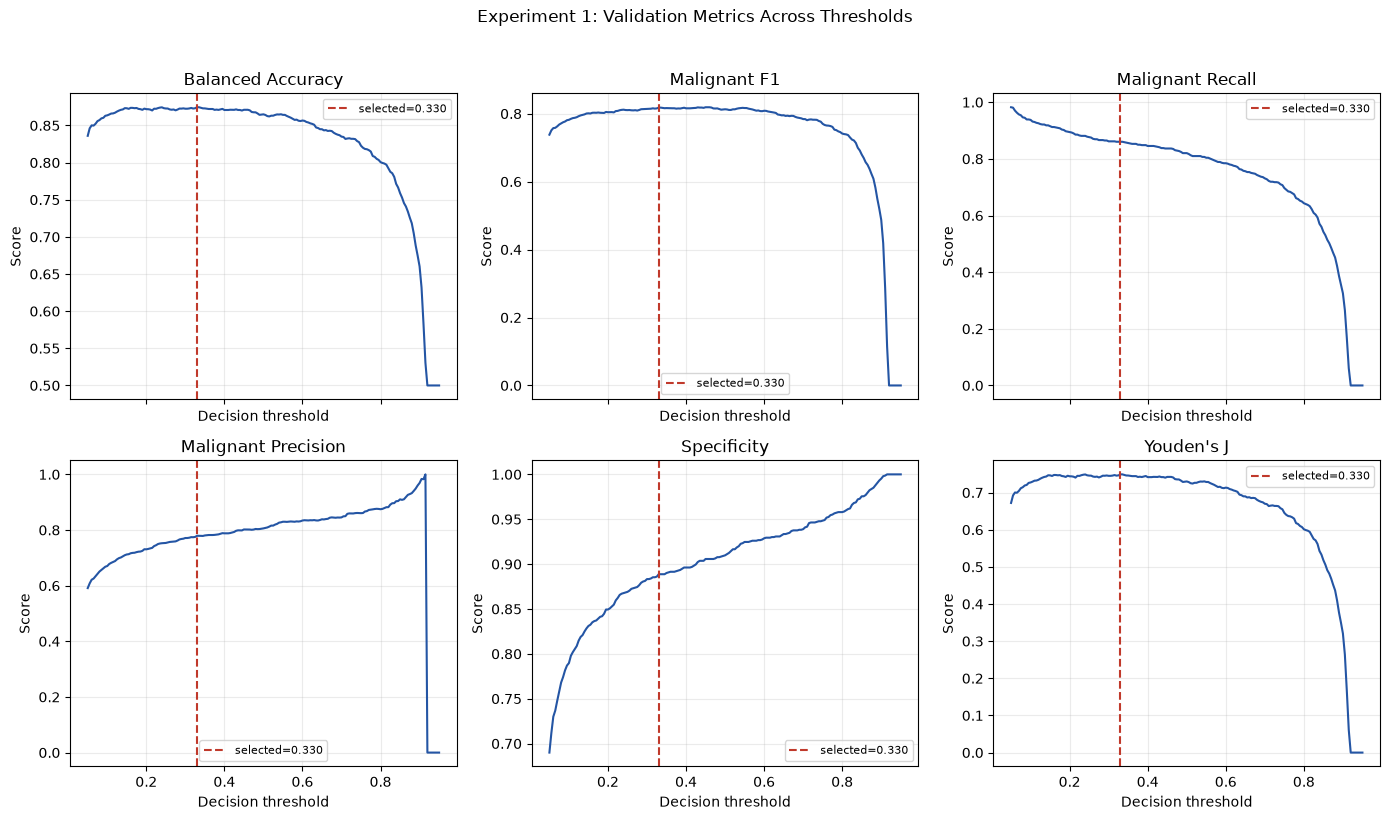

2026-08-22 20:44:09,642 | INFO | Selected Experiment 1 threshold: 0.330 (Balanced-Accuracy-optimal)


,candidate,threshold,balanced_accuracy,f1_score,macro_f1,recall,precision,specificity,youden_j,ba_malignant_f1_score
0,Balanced-Accuracy-optimal,0.33,0.874533,0.817797,0.864076,0.860327,0.779273,0.888738,0.749065,0.846165
1,Youden's-J-optimal,0.33,0.874533,0.817797,0.864076,0.860327,0.779273,0.888738,0.749065,0.846165
2,Constrained BA (Recall >= 0.8279),0.33,0.874533,0.817797,0.864076,0.860327,0.779273,0.888738,0.749065,0.846165
3,F1-optimal (current),0.45,0.871126,0.818909,0.866803,0.836553,0.801994,0.905699,0.742252,0.845017


In [8]:
CURRENT_BASELINE_RECALL = 0.8279
thresholds = np.round(np.arange(0.05, 0.9501, 0.005), 3)

def classification_metrics(labels, probabilities, threshold, include_auc=True):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    recall = recall_score(labels, predictions, zero_division=0)
    precision = precision_score(labels, predictions, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else float('nan')
    # NOTE (added): f1_score above is already Malignant F1 (sklearn's default pos_label=1) -
    # 'malignant_f1' is added as an explicit, unambiguous alias of the same value, and macro_f1
    # is added for context/reporting only. Per an explicit methodology review earlier in this
    # project: Micro F1 is mathematically identical to Accuracy for binary classification, so it
    # cannot serve as a meaningful second primary objective - Balanced Accuracy + Malignant F1
    # are used as the two primary objectives instead (see the threshold-selection score below).
    malignant_f1 = f1_score(labels, predictions, zero_division=0)
    benign_f1 = f1_score(labels, predictions, pos_label=0, zero_division=0)
    output = {
        'threshold': float(threshold),
        'accuracy': accuracy_score(labels, predictions),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'f1_score': malignant_f1,
        'malignant_f1': malignant_f1,
        'benign_f1': benign_f1,
        'macro_f1': (malignant_f1 + benign_f1) / 2.0,
        'recall': recall,
        'precision': precision,
        'specificity': specificity,
        'youden_j': recall + specificity - 1.0,
        'true_negatives': int(tn),
        'false_positives': int(fp),
        'false_negatives': int(fn),
        'true_positives': int(tp),
    }
    if include_auc:
        output.update({
            'roc_auc': roc_auc_score(labels, probabilities),
            'pr_auc': average_precision_score(labels, probabilities),
            'brier_score': brier_score_loss(labels, probabilities),
        })
    return output

threshold_rows = [
    classification_metrics(val_labels, baseline_val_probs, threshold, include_auc=False)
    for threshold in thresholds
]
threshold_sweep = pd.DataFrame(threshold_rows)
threshold_sweep.to_csv(OUTPUT_DIR / 'threshold_sweep_validation.csv', index=False)

def row_at_max(frame, column):
    return frame.loc[frame[column].idxmax()].copy()

candidates = {
    'F1-optimal (current)': row_at_max(threshold_sweep, 'f1_score'),
    'Balanced-Accuracy-optimal': row_at_max(threshold_sweep, 'balanced_accuracy'),
    "Youden's-J-optimal": row_at_max(threshold_sweep, 'youden_j'),
}
feasible = threshold_sweep[threshold_sweep['recall'] >= CURRENT_BASELINE_RECALL]
if feasible.empty:
    logger.warning('No threshold met Recall >= %.4f; constrained row uses the highest-recall grid point.', CURRENT_BASELINE_RECALL)
    constrained_row = threshold_sweep.sort_values(['recall', 'balanced_accuracy'], ascending=False).iloc[0].copy()
else:
    constrained_row = row_at_max(feasible, 'balanced_accuracy')
candidates['Constrained BA (Recall >= 0.8279)'] = constrained_row

candidate_rows = []
for candidate_name, row in candidates.items():
    record = row.to_dict()
    record['candidate'] = candidate_name
    # PRIMARY OBJECTIVE (confirmed): mean(Balanced Accuracy, Malignant F1) only - not a 5-metric
    # average. Micro F1 was considered and rejected as a second objective because it is
    # mathematically identical to Accuracy for a binary problem (see the note in
    # classification_metrics() above), so it cannot add information beyond Balanced Accuracy on
    # its own. Recall/Precision/Specificity/macro_f1 remain fully reported below for context.
    record['ba_malignant_f1_score'] = np.mean([record['balanced_accuracy'], record['f1_score']])
    candidate_rows.append(record)
threshold_candidates = pd.DataFrame(candidate_rows)
threshold_candidates = threshold_candidates[
    ['candidate', 'threshold', 'balanced_accuracy', 'f1_score', 'macro_f1', 'recall', 'precision',
     'specificity', 'youden_j', 'ba_malignant_f1_score']
]
threshold_candidates = threshold_candidates.sort_values(
    ['ba_malignant_f1_score', 'balanced_accuracy', 'f1_score'], ascending=False
).reset_index(drop=True)
selected_threshold = float(threshold_candidates.iloc[0]['threshold'])
selected_threshold_candidate = str(threshold_candidates.iloc[0]['candidate'])
threshold_candidates.to_csv(OUTPUT_DIR / 'threshold_candidates_validation.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
metrics_to_plot = [
    ('balanced_accuracy', 'Balanced Accuracy'),
    ('f1_score', 'Malignant F1'),
    ('recall', 'Malignant Recall'),
    ('precision', 'Malignant Precision'),
    ('specificity', 'Specificity'),
    ('youden_j', "Youden's J"),
]
for axis, (metric_name, title) in zip(axes.flat, metrics_to_plot):
    axis.plot(threshold_sweep['threshold'], threshold_sweep[metric_name], color='#2455a4')
    axis.axvline(selected_threshold, color='#c0392b', linestyle='--', label=f'selected={selected_threshold:.3f}')
    axis.set_title(title)
    axis.set_xlabel('Decision threshold')
    axis.set_ylabel('Score')
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.suptitle('Experiment 1: Validation Metrics Across Thresholds', y=1.02)
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / 'threshold_sweep_metrics.png', bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

logger.info('Selected Experiment 1 threshold: %.3f (%s)', selected_threshold, selected_threshold_candidate)
threshold_candidates

## 8. Experiment 2 — One fine-tuning pace-fix retrain

This is the only retraining run in the notebook. It uses the same architecture, loss, augmentation,
TTA, calibration method, scheduler, batch size, epoch limit, and early-stopping rule as the
baseline. The only bundled changes are the specified pace fixes:

| Setting | Original | Pace-fix run |
|---|---:|---:|
| Frozen warmup | 2 epochs | 4 epochs |
| Backbone learning rate | 1e-4 | 5e-5 |
| Weight decay | 1e-4 | 5e-4 |

Optional label smoothing is intentionally not added, so the requested run changes only the three
mandatory pace-fix settings.

train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 20:48:20,950 | INFO | [pace-fix epoch 1/20] train_loss=0.1142 train_auc=0.8291 train_acc=0.7508 | val_loss=0.1021 val_auc=0.8730 val_acc=0.7727


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 20:50:25,412 | INFO | [pace-fix epoch 2/20] train_loss=0.1072 train_auc=0.8528 train_acc=0.7650 | val_loss=0.0988 val_auc=0.8795 val_acc=0.7941


... (50 outputs left out)

2026-08-22 21:36:18,777 | INFO | [pace-fix epoch 19/20] train_loss=0.0265 train_auc=0.9927 train_acc=0.9588 | val_loss=0.1327 val_auc=0.9384 val_acc=0.8687


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 21:39:05,434 | INFO | [pace-fix epoch 20/20] train_loss=0.0240 train_auc=0.9938 train_acc=0.9611 | val_loss=0.1452 val_auc=0.9374 val_acc=0.8705


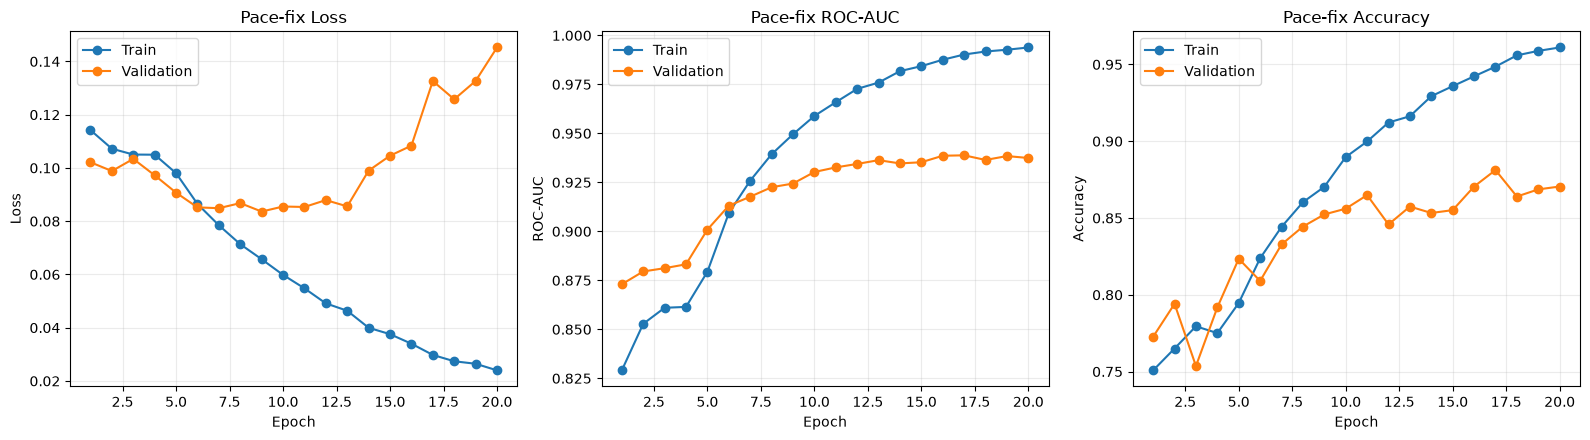

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

In [9]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, run_config=None):
    run_config = CONFIG if run_config is None else run_config
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0
    probabilities, labels = [], []
    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, batch_labels, _ in tqdm(loader, desc='train' if is_train else 'eval', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            batch_labels = batch_labels.to(DEVICE, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=run_config['use_amp']):
                logits = model(images)
                loss = criterion(logits, batch_labels)
            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), run_config['grad_clip_norm'])
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(batch_labels.detach().cpu().numpy())
    probabilities = np.concatenate(probabilities)
    labels = np.concatenate(labels).astype(int)
    loss_value = total_loss / len(loader.dataset)
    auc_value = roc_auc_score(labels, probabilities)
    acc_value = accuracy_score(labels, (probabilities >= 0.5).astype(int))
    return loss_value, auc_value, acc_value

pace_fix_config = dict(CONFIG)
pace_fix_config.update({
    'warmup_freeze_epochs': 4,
    'backbone_lr': 5e-5,
    'weight_decay': 5e-4,
    'label_smoothing': 0.0,
    'experiment': 'fine_tuning_pace_fix',
})

set_seed(RANDOM_STATE)
pace_fix_model = EfficientNetB3BinaryClassifier().to(DEVICE)
pace_fix_criterion = ClassBalancedFocalLoss(
    samples_per_class=[
        int((train_df['binary_label'] == 0).sum()),
        int((train_df['binary_label'] == 1).sum()),
    ],
    beta=pace_fix_config['cb_beta'],
    gamma=pace_fix_config['focal_gamma'],
    device=DEVICE,
)
pace_fix_optimizer = torch.optim.AdamW(
    pace_fix_model.head_parameters(),
    lr=pace_fix_config['head_lr'],
    weight_decay=pace_fix_config['weight_decay'],
)
pace_fix_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    pace_fix_optimizer, mode='max', factor=0.5, patience=2
)
pace_fix_scaler = GradScaler(enabled=pace_fix_config['use_amp'])

pace_fix_history = []
pace_fix_best_state = None
pace_fix_best_val_auc = -np.inf
epochs_without_improvement = 0
for epoch in range(1, pace_fix_config['epochs'] + 1):
    if epoch == pace_fix_config['warmup_freeze_epochs'] + 1:
        pace_fix_model.unfreeze_backbone()
        pace_fix_optimizer.add_param_group({
            'params': pace_fix_model.backbone_trainable_parameters(),
            'lr': pace_fix_config['backbone_lr'],
        })
        logger.info('Pace-fix unfreeze at epoch %d; backbone lr=%.1e', epoch, pace_fix_config['backbone_lr'])

    train_loss, train_auc, train_acc = run_epoch(
        pace_fix_model, train_loader, pace_fix_criterion,
        pace_fix_optimizer, pace_fix_scaler, pace_fix_config
    )
    val_loss, val_auc, val_acc = run_epoch(
        pace_fix_model, val_loader, pace_fix_criterion, None, None, pace_fix_config
    )
    pace_fix_scheduler.step(val_auc)
    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_auc': train_auc,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_auc': val_auc,
        'val_acc': val_acc,
    }
    pace_fix_history.append(row)
    logger.info(
        '[pace-fix epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | '
        'val_loss=%.4f val_auc=%.4f val_acc=%.4f',
        epoch, pace_fix_config['epochs'], train_loss, train_auc, train_acc,
        val_loss, val_auc, val_acc,
    )
    if val_auc > pace_fix_best_val_auc:
        pace_fix_best_val_auc = val_auc
        pace_fix_best_state = {
            'model_state': {key: value.detach().cpu().clone() for key, value in pace_fix_model.state_dict().items()},
            'epoch': epoch,
            'val_auc': val_auc,
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= pace_fix_config['early_stopping_patience']:
            logger.info('Pace-fix early stopping at epoch %d.', epoch)
            break

if pace_fix_best_state is None:
    raise RuntimeError('Pace-fix training did not produce a best checkpoint.')
pace_fix_model.load_state_dict(pace_fix_best_state['model_state'])
pace_fix_history_df = pd.DataFrame(pace_fix_history)
pace_fix_history_df.to_csv(OUTPUT_DIR / 'training_history_pace_fix.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, metric, ylabel in zip(
    axes,
    ['loss', 'auc', 'acc'],
    ['Loss', 'ROC-AUC', 'Accuracy'],
):
    axis.plot(pace_fix_history_df['epoch'], pace_fix_history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(pace_fix_history_df['epoch'], pace_fix_history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set_xlabel('Epoch')
    axis.set_ylabel(ylabel)
    axis.set_title(f'Pace-fix {ylabel}')
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / 'fine_tuning_pace_fix_curves.png', bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

if CONFIG['use_tta']:
    pace_fix_val_raw, pace_fix_val_labels, pace_fix_val_ids = collect_probs_tta(
        pace_fix_model, val_df, tta_transforms
    )
else:
    pace_fix_val_raw, pace_fix_val_labels, pace_fix_val_ids = collect_probs_single(
        pace_fix_model, val_loader
    )
if not np.array_equal(val_labels, pace_fix_val_labels) or val_ids != pace_fix_val_ids:
    raise RuntimeError('Validation ordering mismatch between baseline and pace-fix inference.')
pace_fix_calibrator = fit_platt_calibrator(pace_fix_val_raw, val_labels)
pace_fix_val_probs = calibrated_probabilities(pace_fix_calibrator, pace_fix_val_raw)

## 8b. Experiment 3 — Weighted Random Sampler retrain

**Problem addressed**: `ClassBalancedFocalLoss` already re-weights the loss contribution of each
sample by class, but every training batch is still *drawn* with the original class proportions
(sampling is unweighted) - the model still sees far more Benign than Malignant images per batch,
just weighted differently once seen. `WeightedRandomSampler` changes what gets *sampled*, giving
genuinely more balanced within-batch class exposure, which is a different mechanism than
reweighting the loss and is not redundant with it.

Everything else is identical to the baseline: same architecture, same loss (still
Class-Balanced Focal, on top of the now-balanced batches), same augmentation, same TTA, same
calibration method, same scheduler, same epoch limit and early-stopping rule, same warmup
schedule (2 epochs, unlike Experiment 2's 4) and the same original learning rates/weight decay
(unlike Experiment 2, which changed those) - this isolates the sampler as the *only* variable,
distinct from Experiment 2's pace-fix changes.

**Confidence**: medium-high. **Cost**: one full retrain (same cost class as Experiment 2).
Compared on validation only, using the same McNemar + practical-significance framework as
Experiment 2, against the currently-leading version (baseline or Experiment 2's result,
whichever validation currently favors).

train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 21:42:24,699 | INFO | [sampler epoch 1/20] train_loss=0.1204 train_auc=0.8288 train_acc=0.7406 | val_loss=0.1031 val_auc=0.8766 val_acc=0.7601


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 21:44:32,526 | INFO | [sampler epoch 2/20] train_loss=0.1099 train_auc=0.8622 train_acc=0.7720 | val_loss=0.1082 val_auc=0.8772 val_acc=0.7420
2026-08-22 21:44:32,569 | INFO | Sampler-experiment unfreeze at epoch 3; backbone lr=1.0e-04


... (50 outputs left out)

2026-08-22 22:33:01,683 | INFO | [sampler epoch 19/20] train_loss=0.0102 train_auc=0.9990 train_acc=0.9857 | val_loss=0.1659 val_auc=0.9413 val_acc=0.8659


train:   0%|          | 0/268 [00:00<?, ?it/s]

eval:   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:35:51,807 | INFO | [sampler epoch 20/20] train_loss=0.0094 train_auc=0.9991 train_acc=0.9854 | val_loss=0.1748 val_auc=0.9419 val_acc=0.8714


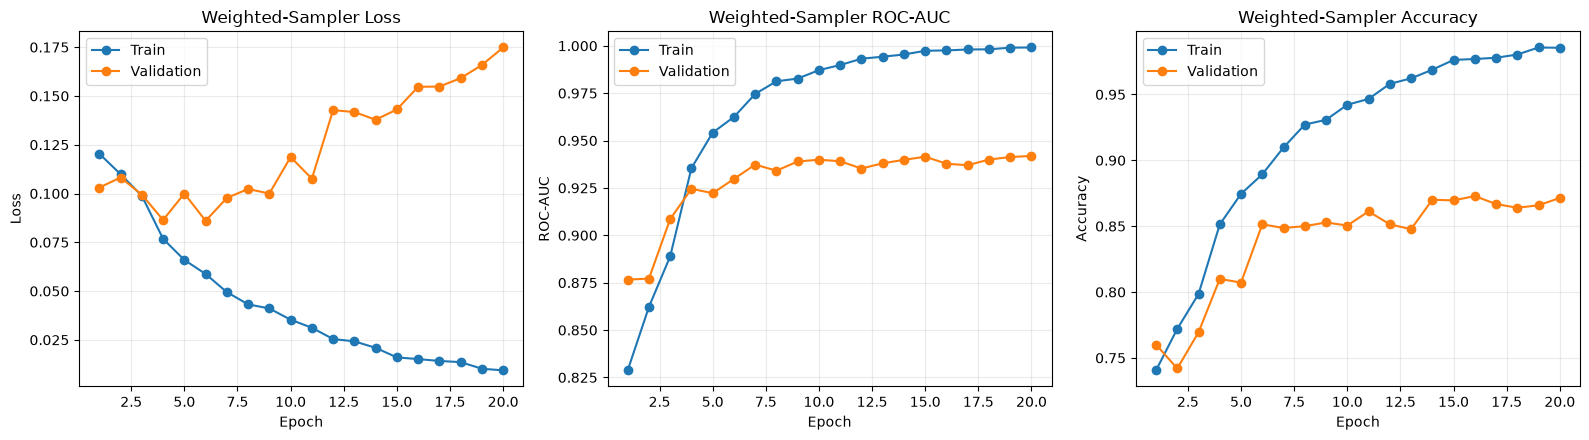

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

In [10]:
sampler_config = dict(CONFIG)
sampler_config['experiment'] = 'weighted_random_sampler'

train_labels_for_sampler = train_df['binary_label'].values
class_sample_counts = np.bincount(train_labels_for_sampler)
per_sample_weight = 1.0 / class_sample_counts[train_labels_for_sampler]
weighted_sampler = torch.utils.data.WeightedRandomSampler(
    weights=torch.as_tensor(per_sample_weight, dtype=torch.double),
    num_samples=len(train_labels_for_sampler),
    replacement=True,
)
sampler_train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'], sampler=weighted_sampler,
    num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True,
)

set_seed(RANDOM_STATE)
sampler_model = EfficientNetB3BinaryClassifier().to(DEVICE)
sampler_criterion = ClassBalancedFocalLoss(
    samples_per_class=[
        int((train_df['binary_label'] == 0).sum()),
        int((train_df['binary_label'] == 1).sum()),
    ],
    beta=sampler_config['cb_beta'], gamma=sampler_config['focal_gamma'], device=DEVICE,
)
sampler_optimizer = torch.optim.AdamW(
    sampler_model.head_parameters(), lr=sampler_config['head_lr'], weight_decay=sampler_config['weight_decay'],
)
sampler_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(sampler_optimizer, mode='max', factor=0.5, patience=2)
sampler_scaler = GradScaler(enabled=sampler_config['use_amp'])

sampler_history = []
sampler_best_state = None
sampler_best_val_auc = -np.inf
epochs_without_improvement = 0
for epoch in range(1, sampler_config['epochs'] + 1):
    if epoch == sampler_config['warmup_freeze_epochs'] + 1:
        sampler_model.unfreeze_backbone()
        sampler_optimizer.add_param_group({
            'params': sampler_model.backbone_trainable_parameters(), 'lr': sampler_config['backbone_lr'],
        })
        logger.info('Sampler-experiment unfreeze at epoch %d; backbone lr=%.1e', epoch, sampler_config['backbone_lr'])

    train_loss, train_auc, train_acc = run_epoch(
        sampler_model, sampler_train_loader, sampler_criterion, sampler_optimizer, sampler_scaler, sampler_config
    )
    val_loss, val_auc, val_acc = run_epoch(sampler_model, val_loader, sampler_criterion, None, None, sampler_config)
    sampler_scheduler.step(val_auc)
    row = {'epoch': epoch, 'train_loss': train_loss, 'train_auc': train_auc, 'train_acc': train_acc,
           'val_loss': val_loss, 'val_auc': val_auc, 'val_acc': val_acc}
    sampler_history.append(row)
    logger.info('[sampler epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | val_loss=%.4f val_auc=%.4f val_acc=%.4f',
                epoch, sampler_config['epochs'], train_loss, train_auc, train_acc, val_loss, val_auc, val_acc)
    if val_auc > sampler_best_val_auc:
        sampler_best_val_auc = val_auc
        sampler_best_state = {
            'model_state': {k: v.detach().cpu().clone() for k, v in sampler_model.state_dict().items()},
            'epoch': epoch, 'val_auc': val_auc,
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= sampler_config['early_stopping_patience']:
            logger.info('Sampler-experiment early stopping at epoch %d.', epoch)
            break

if sampler_best_state is None:
    raise RuntimeError('Weighted-sampler training did not produce a best checkpoint.')
sampler_model.load_state_dict(sampler_best_state['model_state'])
sampler_history_df = pd.DataFrame(sampler_history)
sampler_history_df.to_csv(OUTPUT_DIR / 'training_history_weighted_sampler.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for axis, metric, ylabel in zip(axes, ['loss', 'auc', 'acc'], ['Loss', 'ROC-AUC', 'Accuracy']):
    axis.plot(sampler_history_df['epoch'], sampler_history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(sampler_history_df['epoch'], sampler_history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set_xlabel('Epoch'); axis.set_ylabel(ylabel); axis.set_title(f'Weighted-Sampler {ylabel}')
    axis.grid(alpha=0.25); axis.legend()
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / 'weighted_sampler_curves.png', bbox_inches='tight', dpi=150)
plt.show()
plt.close(fig)

if CONFIG['use_tta']:
    sampler_val_raw, sampler_val_labels, sampler_val_ids = collect_probs_tta(sampler_model, val_df, tta_transforms)
else:
    sampler_val_raw, sampler_val_labels, sampler_val_ids = collect_probs_single(sampler_model, val_loader)
if not np.array_equal(val_labels, sampler_val_labels) or val_ids != sampler_val_ids:
    raise RuntimeError('Validation ordering mismatch between baseline and weighted-sampler inference.')
sampler_calibrator = fit_platt_calibrator(sampler_val_raw, val_labels)
sampler_val_probs = calibrated_probabilities(sampler_calibrator, sampler_val_raw)


## 9. Validation comparison and locked image-only model decision

This section compares the original image-only candidates (Baseline, the pace-fix retrain, and
the weighted-sampler retrain) and locks the strongest image-only version before the late-fusion
extension. The late-fusion candidate is compared against this locked image-only winner in Section 13.

McNemar's exact two-sided test is reported for the image-only retrains independently. An
improvement is treated as meaningful only when it improves the **primary objective**
(`mean(Balanced Accuracy, Malignant F1)`), does not clearly break Precision or Specificity (drop
greater than 0.02), and is supported by either McNemar's test at p < 0.05 or at least 15
additional malignant true positives on validation. If more than one retrain passes these checks,
the one with the higher primary-objective score is selected.

In [11]:
baseline_validation_metrics = classification_metrics(
    val_labels, baseline_val_probs, baseline_threshold, include_auc=True
)
threshold_only_validation_metrics = classification_metrics(
    val_labels, baseline_val_probs, selected_threshold, include_auc=True
)
pace_fix_validation_metrics = classification_metrics(
    val_labels, pace_fix_val_probs, selected_threshold, include_auc=True
)
sampler_validation_metrics = classification_metrics(
    val_labels, sampler_val_probs, selected_threshold, include_auc=True
)

validation_comparison = pd.DataFrame([
    {'version': 'Baseline', **baseline_validation_metrics},
    {'version': 'Threshold-only', **threshold_only_validation_metrics},
    {'version': 'Fine-tuning-fix (+ threshold)', **pace_fix_validation_metrics},
    {'version': 'Weighted-Sampler (+ threshold)', **sampler_validation_metrics},
])
for _df_row in [validation_comparison]:
    _df_row['ba_malignant_f1_score'] = _df_row[['balanced_accuracy', 'malignant_f1']].mean(axis=1)
validation_comparison = validation_comparison[
    ['version', 'threshold', 'balanced_accuracy', 'malignant_f1', 'macro_f1', 'ba_malignant_f1_score',
     'recall', 'precision', 'specificity', 'roc_auc', 'pr_auc', 'brier_score']
]
validation_comparison.to_csv(OUTPUT_DIR / 'validation_comparison.csv', index=False)

def exact_mcnemar(labels, baseline_predictions, new_predictions):
    baseline_correct = baseline_predictions == labels
    new_correct = new_predictions == labels
    b = int(np.sum(baseline_correct & ~new_correct))
    c = int(np.sum(~baseline_correct & new_correct))
    discordant = b + c
    if discordant == 0:
        p_value = 1.0
    else:
        lower_tail = sum(math.comb(discordant, k) for k in range(0, min(b, c) + 1)) / (2 ** discordant)
        p_value = min(1.0, 2.0 * lower_tail)
    return {'b_baseline_only_correct': b, 'c_new_only_correct': c, 'discordant_pairs': discordant, 'p_value': p_value}


def evaluate_candidate(name, probs, metrics):
    baseline_val_predictions = (baseline_val_probs >= baseline_threshold).astype(int)
    new_val_predictions = (probs >= selected_threshold).astype(int)
    mcnemar = exact_mcnemar(val_labels, baseline_val_predictions, new_val_predictions)
    net_malignant_tp_gain = metrics['true_positives'] - baseline_validation_metrics['true_positives']
    primary_improvement = metrics['ba_malignant_f1_score'] if 'ba_malignant_f1_score' in metrics else np.mean(
        [metrics['balanced_accuracy'], metrics['malignant_f1']]
    )
    baseline_primary = np.mean([baseline_validation_metrics['balanced_accuracy'], baseline_validation_metrics['malignant_f1']])
    no_precision_break = metrics['precision'] >= baseline_validation_metrics['precision'] - 0.02
    no_specificity_break = metrics['specificity'] >= baseline_validation_metrics['specificity'] - 0.02
    statistically_or_practically_supported = mcnemar['p_value'] < 0.05 or net_malignant_tp_gain >= 15
    passes = bool(
        primary_improvement > baseline_primary
        and no_precision_break and no_specificity_break
        and statistically_or_practically_supported
    )
    return {
        'name': name, 'primary_objective_score': float(primary_improvement), 'mcnemar': mcnemar,
        'net_malignant_true_positive_gain': int(net_malignant_tp_gain),
        'no_precision_break': no_precision_break, 'no_specificity_break': no_specificity_break,
        'statistically_or_practically_supported': statistically_or_practically_supported,
        'passes_all_checks': passes,
    }


sampler_validation_metrics['ba_malignant_f1_score'] = float(np.mean(
    [sampler_validation_metrics['balanced_accuracy'], sampler_validation_metrics['malignant_f1']]
))
pace_fix_validation_metrics['ba_malignant_f1_score'] = float(np.mean(
    [pace_fix_validation_metrics['balanced_accuracy'], pace_fix_validation_metrics['malignant_f1']]
))
baseline_validation_metrics['ba_malignant_f1_score'] = float(np.mean(
    [baseline_validation_metrics['balanced_accuracy'], baseline_validation_metrics['malignant_f1']]
))

pace_fix_evaluation = evaluate_candidate('Fine-tuning-fix (+ threshold)', pace_fix_val_probs, pace_fix_validation_metrics)
sampler_evaluation = evaluate_candidate('Weighted-Sampler (+ threshold)', sampler_val_probs, sampler_validation_metrics)
candidate_evaluations = [pace_fix_evaluation, sampler_evaluation]

passing_candidates = [c for c in candidate_evaluations if c['passes_all_checks']]
if passing_candidates:
    winner = max(passing_candidates, key=lambda c: c['primary_objective_score'])
    selected_version = winner['name']
else:
    winner = None
    selected_version = 'Threshold-only'

if selected_version == 'Fine-tuning-fix (+ threshold)':
    selected_model, selected_calibrator = pace_fix_model, pace_fix_calibrator
    selected_val_raw, selected_val_probs, selected_val_ids = pace_fix_val_raw, pace_fix_val_probs, pace_fix_val_ids
    selected_model_state = pace_fix_best_state['model_state']
elif selected_version == 'Weighted-Sampler (+ threshold)':
    selected_model, selected_calibrator = sampler_model, sampler_calibrator
    selected_val_raw, selected_val_probs, selected_val_ids = sampler_val_raw, sampler_val_probs, sampler_val_ids
    selected_model_state = sampler_best_state['model_state']
else:
    selected_model, selected_calibrator = baseline_model, baseline_calibrator
    selected_val_raw, selected_val_probs, selected_val_ids = baseline_val_raw, baseline_val_probs, val_ids
    selected_model_state = original_checkpoint['model_state']

# Kept for downstream cells (Section 10/11) that reference these flags by their original names.
pace_fix_is_final = bool(selected_version == 'Fine-tuning-fix (+ threshold)')

decision_summary = {
    'selected_version': selected_version,
    'selected_threshold': selected_threshold,
    'selected_threshold_candidate': selected_threshold_candidate,
    'primary_objective': 'mean(balanced_accuracy, malignant_f1)',
    'baseline_primary_objective_score': float(baseline_validation_metrics['ba_malignant_f1_score']),
    'candidate_evaluations': candidate_evaluations,
}
with open(OUTPUT_DIR / 'validation_decision.json', 'w') as handle:
    json.dump(decision_summary, handle, indent=2, default=str)

logger.info('Validation decision (3-way comparison, primary objective = mean(Balanced Accuracy, Malignant F1)): %s',
            json.dumps(decision_summary, indent=2, default=str))
validation_comparison.round(4)


2026-08-22 22:37:01,792 | INFO | Validation decision (3-way comparison, primary objective = mean(Balanced Accuracy, Malignant F1)): {
  "selected_version": "Threshold-only",
  "selected_threshold": 0.33,
  "selected_threshold_candidate": "Balanced-Accuracy-optimal",
  "primary_objective": "mean(balanced_accuracy, malignant_f1)",
  "baseline_primary_objective_score": 0.8461645605963274,
  "candidate_evaluations": [
    {
      "name": "Fine-tuning-fix (+ threshold)",
      "primary_objective_score": 0.8357320371620862,
      "mcnemar": {
        "b_baseline_only_correct": 89,
        "c_new_only_correct": 72,
        "discordant_pairs": 161,
        "p_value": 0.20717984725922248
      },
      "net_malignant_true_positive_gain": -8,
      "no_precision_break": true,
      "no_specificity_break": "True",
      "statistically_or_practically_supported": false,
      "passes_all_checks": false
    },
    {
      "name": "Weighted-Sampler (+ threshold)",
      "primary_objective_score": 0.8

,version,threshold,balanced_accuracy,malignant_f1,macro_f1,ba_malignant_f1_score,recall,precision,specificity,roc_auc,pr_auc,brier_score
0,Baseline,0.33,0.8745,0.8178,0.8641,0.8462,0.8603,0.7793,0.8887,0.9480,0.8910,0.0875
1,Threshold-only,0.33,0.8745,0.8178,0.8641,0.8462,0.8603,0.7793,0.8887,0.9480,0.8910,0.0875
2,Fine-tuning-fix (+ threshold),0.33,0.8655,0.8059,0.8552,0.8357,0.8484,0.7675,0.8826,0.9437,0.8841,0.0886
3,Weighted-Sampler (+ threshold),0.33,0.8630,0.8028,0.8530,0.8329,0.8440,0.7655,0.8820,0.9440,0.8827,0.0923


## 10. Metadata preprocessing and alignment

This extension is deliberately additive. The image-only cells above are retained unchanged through
validation model selection. Metadata is attached to the same split DataFrames by `image_id`, then
preprocessed by a reusable transformer fitted only on `train_df`. Validation, test, and future inference
rows use `.transform()` only.

In [12]:
METADATA_COLUMNS = ['age', 'sex', 'localization']


def attach_metadata_columns(df: pd.DataFrame, name: str) -> pd.DataFrame:
    result = df.copy()
    missing = [column for column in METADATA_COLUMNS if column not in result.columns]
    if not missing:
        return result

    candidate_names = ['HAM10000_metadata.csv', 'full_metadata.csv', 'metadata.csv', 'ISIC_metadata.csv']
    candidate_locations = [METADATA_DIR, DATASET_DIR, PROJECT_ROOT / 'Data']
    source_path = next(
        (
            location / filename
            for location in candidate_locations
            for filename in candidate_names
            if (location / filename).exists()
        ),
        None,
    )
    if source_path is None:
        raise FileNotFoundError(
            f'{name}: missing metadata columns {missing}. Add them to the split CSV or provide one of '
            f'{candidate_names} under {METADATA_DIR}, {DATASET_DIR}, or {PROJECT_ROOT / "Data"}.'
        )
    source = pd.read_csv(source_path)
    if 'image_id' not in source.columns:
        raise ValueError(f'{source_path} must contain image_id for safe metadata alignment.')
    missing_in_source = [column for column in missing if column not in source.columns]
    if missing_in_source:
        raise ValueError(f'{source_path} is missing required metadata columns: {missing_in_source}')
    source_columns = ['image_id'] + missing
    result = result.merge(source[source_columns], on='image_id', how='left', validate='many_to_one')
    if len(result) != len(df):
        raise RuntimeError(f'{name}: metadata merge changed the number of rows.')
    logger.info('%s: attached metadata from %s', name, source_path)
    return result


train_df = attach_metadata_columns(train_df, 'train')
val_df = attach_metadata_columns(val_df, 'validation')
test_df = attach_metadata_columns(test_df, 'test')


class TrainOnlyMetadataPreprocessor:
    """Train-only age imputation/scaling and categorical one-hot encoding."""

    def __init__(self):
        self.age_imputer = SimpleImputer(strategy='median')
        self.age_scaler = StandardScaler()
        try:
            self.encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError:
            self.encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
        self.feature_dim = None
        self._fitted = False

    @staticmethod
    def _age_frame(df):
        return pd.DataFrame({'age': pd.to_numeric(df['age'], errors='coerce')}, index=df.index)

    @staticmethod
    def _categorical_frame(df):
        result = df[['sex', 'localization']].copy()
        for column in ['sex', 'localization']:
            result[column] = result[column].where(result[column].notna(), 'unknown').astype(str)
            result[column] = result[column].replace({'': 'unknown', 'nan': 'unknown', 'None': 'unknown'})
        return result

    def fit(self, train_frame):
        missing = set(METADATA_COLUMNS) - set(train_frame.columns)
        if missing:
            raise ValueError(f'Train metadata is missing columns: {sorted(missing)}')
        age_values = self.age_imputer.fit_transform(self._age_frame(train_frame))
        if not np.isfinite(self.age_imputer.statistics_[0]):
            self.age_imputer.statistics_[0] = 0.0
            age_values = self.age_imputer.transform(self._age_frame(train_frame))
        self.age_scaler.fit(age_values)
        self.encoder.fit(self._categorical_frame(train_frame))
        self.feature_dim = int(1 + len(self.encoder.get_feature_names_out()))
        self._fitted = True
        return self

    def transform(self, frame):
        if not self._fitted:
            raise RuntimeError('Fit the metadata preprocessor on train data before calling transform.')
        age = self.age_scaler.transform(
            self.age_imputer.transform(self._age_frame(frame))
        ).astype(np.float32)
        categorical = self.encoder.transform(self._categorical_frame(frame)).astype(np.float32)
        result = np.concatenate([age, categorical], axis=1).astype(np.float32)
        if result.shape[1] != self.feature_dim or not np.isfinite(result).all():
            raise RuntimeError('Metadata transformation produced an invalid shape or non-finite value.')
        return result

    def neutral_vector(self):
        if not self._fitted:
            raise RuntimeError('Fit the metadata preprocessor before requesting a neutral vector.')
        neutral_frame = pd.DataFrame({'age': [self.age_imputer.statistics_[0]], 'sex': ['unknown'], 'localization': ['unknown']})
        return self.transform(neutral_frame)[0]

    def to_dict(self):
        if not self._fitted:
            raise RuntimeError('Cannot serialize an unfitted metadata preprocessor.')
        return {
            'metadata_columns': METADATA_COLUMNS,
            'age_imputer_strategy': 'median',
            'age_median': float(self.age_imputer.statistics_[0]),
            'age_scaler_mean': self.age_scaler.mean_.tolist(),
            'age_scaler_scale': self.age_scaler.scale_.tolist(),
            'categories': [list(values) for values in self.encoder.categories_],
            'feature_dim': int(self.feature_dim),
            'neutral_vector': self.neutral_vector().tolist(),
        }


metadata_preprocessor = TrainOnlyMetadataPreprocessor().fit(train_df)
train_metadata = metadata_preprocessor.transform(train_df)
val_metadata = metadata_preprocessor.transform(val_df)
test_metadata = metadata_preprocessor.transform(test_df)
METADATA_DIM = int(metadata_preprocessor.feature_dim)
assert train_metadata.shape == (len(train_df), METADATA_DIM)
assert val_metadata.shape == (len(val_df), METADATA_DIM)
assert test_metadata.shape == (len(test_df), METADATA_DIM)
logger.info('Train-only metadata preprocessing complete; feature dimension=%d.', METADATA_DIM)

2026-08-22 22:37:01,896 | INFO | Train-only metadata preprocessing complete; feature dimension=25.


## 11. Late-fusion model and compatible checkpoint reuse

The model is a simple late-fusion baseline: EfficientNet-B3 image embedding, a small metadata MLP,
concatenation, and a regularized binary classification head. The existing image-only checkpoint is
archived before the candidate is trained. Only compatible backbone tensors are reused; the metadata
MLP and fusion classifier are newly initialized.

In [13]:
BASELINE_ARCHIVE_PATH = CHECKPOINTS_DIR / 'baseline_image_only_best_model.pth'
if not BASELINE_ARCHIVE_PATH.exists():
    if not original_checkpoint_path.exists():
        raise FileNotFoundError(f'Cannot archive missing image-only checkpoint: {original_checkpoint_path}')
    torch.save(original_checkpoint, BASELINE_ARCHIVE_PATH)
    logger.info('Archived image-only checkpoint at %s', BASELINE_ARCHIVE_PATH)


class SkinLesionMultimodalDataset(Dataset):
    def __init__(self, df: pd.DataFrame, metadata_features: np.ndarray, transform):
        self.df = df.reset_index(drop=True)
        self.metadata_features = np.asarray(metadata_features, dtype=np.float32)
        self.transform = transform
        if len(self.df) != len(self.metadata_features):
            raise ValueError('Image and metadata row counts do not match.')

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row['image_path']) as image:
            image = image.convert('RGB')
        image = self.transform(image)
        metadata = torch.from_numpy(self.metadata_features[index])
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        return image, metadata, label, row['image_id']


class EfficientNetB3LateFusionClassifier(nn.Module):
    def __init__(self, metadata_dim: int):
        super().__init__()
        self.weights = torchvision.models.EfficientNet_B3_Weights.IMAGENET1K_V1
        self.backbone = torchvision.models.efficientnet_b3(weights=self.weights)
        self.image_feature_dim = int(self.backbone.classifier[1].in_features)
        self.backbone.classifier = nn.Identity()
        self.metadata_mlp = nn.Sequential(
            nn.Linear(metadata_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(inplace=True),
        )
        self.classifier = nn.Sequential(
            nn.Linear(self.image_feature_dim + 32, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 1),
        )
        self.backbone_frozen = True
        self.freeze_backbone()

    def forward(self, image, metadata):
        if metadata is None:
            raise ValueError('Late-fusion inference requires metadata.')
        image_features = self.backbone(image)
        metadata_features = self.metadata_mlp(metadata)
        return self.classifier(torch.cat([image_features, metadata_features], dim=1)).squeeze(1)

    def freeze_backbone(self):
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False
        self.backbone_frozen = True

    def unfreeze_backbone(self):
        for parameter in self.backbone.parameters():
            parameter.requires_grad = True
        self.backbone_frozen = False

    def backbone_trainable_parameters(self):
        return [parameter for parameter in self.backbone.parameters() if parameter.requires_grad]


def compatible_backbone_state(source_state):
    normalized = {}
    for raw_key, value in source_state.items():
        key = raw_key[7:] if raw_key.startswith('module.') else raw_key
        normalized[key] = value
    return normalized


def load_compatible_backbone_weights(model, source_state):
    source_state = compatible_backbone_state(source_state)
    target_state = model.state_dict()
    compatible = {
        key: value for key, value in source_state.items()
        if key.startswith('backbone.') and key in target_state and target_state[key].shape == value.shape
    }
    if not compatible:
        raise RuntimeError('No compatible EfficientNet-B3 backbone tensors found in the source checkpoint.')
    result = model.load_state_dict(compatible, strict=False)
    skipped = [key for key in source_state if key.startswith('backbone.') and key not in compatible]
    logger.info(
        'Loaded %d compatible backbone tensors; new fusion-head tensors remain initialized. '
        'Missing target keys=%d; skipped source backbone keys=%d.',
        len(compatible), len(result.missing_keys), len(skipped),
    )
    return result


set_seed(RANDOM_STATE)
multimodal_model = EfficientNetB3LateFusionClassifier(metadata_dim=METADATA_DIM).to(DEVICE)
load_compatible_backbone_weights(multimodal_model, selected_model_state)

2026-08-22 22:37:02,077 | INFO | Loaded 572 compatible backbone tensors; new fusion-head tensors remain initialized. Missing target keys=16; skipped source backbone keys=2.


_IncompatibleKeys(missing_keys=['metadata_mlp.0.weight', 'metadata_mlp.0.bias', 'metadata_mlp.1.weight', 'metadata_mlp.1.bias', 'metadata_mlp.1.running_mean', 'metadata_mlp.1.running_var', 'metadata_mlp.4.weight', 'metadata_mlp.4.bias', 'classifier.0.weight', 'classifier.0.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.1.running_mean', 'classifier.1.running_var', 'classifier.4.weight', 'classifier.4.bias'], unexpected_keys=[])

## 12. Late-fusion training with discriminative learning rates

The candidate keeps the existing class-balanced focal loss and training controls. The backbone is
frozen while the new heads learn, then unfrozen with a learning rate substantially below the metadata
and fusion-head learning rates.

In [14]:
multimodal_config = dict(CONFIG)
multimodal_config.update({
    'experiment': 'late_fusion_metadata',
    'metadata_lr': 1e-3,
    'classifier_lr': 1e-3,
    'backbone_lr': 5e-5,
    'warmup_freeze_epochs': 3,
})

train_dataset_mm = SkinLesionMultimodalDataset(train_df, train_metadata, train_transform)
val_dataset_mm = SkinLesionMultimodalDataset(val_df, val_metadata, eval_transform)
train_loader_mm = DataLoader(
    train_dataset_mm, batch_size=multimodal_config['batch_size'], shuffle=True,
    num_workers=multimodal_config['num_workers'], pin_memory=True, drop_last=True,
)
val_loader_mm = DataLoader(
    val_dataset_mm, batch_size=multimodal_config['batch_size'], shuffle=False,
    num_workers=multimodal_config['num_workers'], pin_memory=True,
)

multimodal_criterion = ClassBalancedFocalLoss(
    samples_per_class=[
        int((train_df['binary_label'] == 0).sum()),
        int((train_df['binary_label'] == 1).sum()),
    ],
    beta=multimodal_config['cb_beta'],
    gamma=multimodal_config['focal_gamma'],
    device=DEVICE,
)
multimodal_optimizer = torch.optim.AdamW(
    [
        {'params': multimodal_model.metadata_mlp.parameters(), 'lr': multimodal_config['metadata_lr']},
        {'params': multimodal_model.classifier.parameters(), 'lr': multimodal_config['classifier_lr']},
    ],
    weight_decay=multimodal_config['weight_decay'],
)
multimodal_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    multimodal_optimizer, mode='max', factor=0.5, patience=2
)
multimodal_scaler = GradScaler(enabled=multimodal_config['use_amp'])


def run_epoch_multimodal(model, loader, criterion, optimizer=None, scaler=None, run_config=None):
    run_config = CONFIG if run_config is None else run_config
    is_train = optimizer is not None
    model.train(is_train)
    if is_train and getattr(model, 'backbone_frozen', False):
        model.backbone.eval()
    total_loss = 0.0
    probabilities, labels = [], []
    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, metadata, batch_labels, _ in tqdm(
            loader, desc='train (late fusion)' if is_train else 'eval (late fusion)', leave=False
        ):
            images = images.to(DEVICE, non_blocking=True)
            metadata = metadata.to(DEVICE, non_blocking=True)
            batch_labels = batch_labels.to(DEVICE, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=run_config['use_amp']):
                logits = model(images, metadata)
                loss = criterion(logits, batch_labels)
            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), run_config['grad_clip_norm'])
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(batch_labels.detach().cpu().numpy())
    probabilities = np.concatenate(probabilities)
    labels = np.concatenate(labels).astype(int)
    return (
        total_loss / len(loader.dataset),
        roc_auc_score(labels, probabilities),
        accuracy_score(labels, (probabilities >= 0.5).astype(int)),
    )


multimodal_history = []
multimodal_best_state = None
multimodal_best_val_auc = -np.inf
epochs_without_improvement = 0
for epoch in range(1, multimodal_config['epochs'] + 1):
    if epoch == multimodal_config['warmup_freeze_epochs'] + 1:
        multimodal_model.unfreeze_backbone()
        multimodal_optimizer.add_param_group({
            'params': multimodal_model.backbone_trainable_parameters(),
            'lr': multimodal_config['backbone_lr'],
        })
        logger.info(
            'Late-fusion backbone unfreezed at epoch %d; backbone lr=%.1e; new-head lr=%.1e.',
            epoch, multimodal_config['backbone_lr'], multimodal_config['metadata_lr'],
        )

    train_loss, train_auc, train_acc = run_epoch_multimodal(
        multimodal_model, train_loader_mm, multimodal_criterion,
        multimodal_optimizer, multimodal_scaler, multimodal_config,
    )
    val_loss, val_auc, val_acc = run_epoch_multimodal(
        multimodal_model, val_loader_mm, multimodal_criterion, None, None, multimodal_config,
    )
    multimodal_scheduler.step(val_auc)
    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_auc': train_auc,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_auc': val_auc,
        'val_acc': val_acc,
    }
    multimodal_history.append(row)
    logger.info(
        '[late-fusion epoch %d/%d] train_loss=%.4f train_auc=%.4f train_acc=%.4f | '
        'val_loss=%.4f val_auc=%.4f val_acc=%.4f',
        epoch, multimodal_config['epochs'], train_loss, train_auc, train_acc,
        val_loss, val_auc, val_acc,
    )
    if val_auc > multimodal_best_val_auc:
        multimodal_best_val_auc = val_auc
        multimodal_best_state = {
            'model_state': {key: value.detach().cpu().clone() for key, value in multimodal_model.state_dict().items()},
            'epoch': epoch,
            'val_auc': val_auc,
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= multimodal_config['early_stopping_patience']:
            logger.info('Late-fusion early stopping at epoch %d.', epoch)
            break

if multimodal_best_state is None:
    raise RuntimeError('Late-fusion training produced no checkpoint.')
multimodal_model.load_state_dict(multimodal_best_state['model_state'])
pd.DataFrame(multimodal_history).to_csv(
    OUTPUT_DIR / 'training_history_late_fusion_metadata.csv', index=False
)

train (late fusion):   0%|          | 0/268 [00:00<?, ?it/s]

eval (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:39:05,010 | INFO | [late-fusion epoch 1/20] train_loss=0.0113 train_auc=0.9986 train_acc=0.9803 | val_loss=0.1471 val_auc=0.9421 val_acc=0.8756


train (late fusion):   0%|          | 0/268 [00:00<?, ?it/s]

eval (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:41:08,043 | INFO | [late-fusion epoch 2/20] train_loss=0.0071 train_auc=0.9994 train_acc=0.9895 | val_loss=0.1592 val_auc=0.9382 val_acc=0.8812


... (8 outputs left out)

2026-08-22 22:48:39,434 | INFO | [late-fusion epoch 5/20] train_loss=0.0132 train_auc=0.9981 train_acc=0.9823 | val_loss=0.1815 val_auc=0.9417 val_acc=0.8770


train (late fusion):   0%|          | 0/268 [00:00<?, ?it/s]

eval (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:51:24,466 | INFO | [late-fusion epoch 6/20] train_loss=0.0133 train_auc=0.9981 train_acc=0.9818 | val_loss=0.1958 val_auc=0.9416 val_acc=0.8766
2026-08-22 22:51:24,466 | INFO | Late-fusion early stopping at epoch 6.


## 13. Unified validation comparison and model decision

Calibration and threshold selection use validation data only. The same primary objective used by the
existing notebook—`mean(Balanced Accuracy, Malignant F1)`—is used to compare the already-selected
image-only winner with the late-fusion candidate. The test set is not read in this section.

In [15]:
@torch.no_grad()
def collect_probs_tta_multimodal(model, df, metadata_features, transform_list, metadata_override=None):
    model.eval()
    view_probabilities = []
    labels_reference = None
    ids_reference = None
    for transform in transform_list:
        features = metadata_features if metadata_override is None else np.repeat(
            np.asarray(metadata_override, dtype=np.float32)[None, :], len(df), axis=0
        )
        dataset = SkinLesionMultimodalDataset(df, features, transform)
        loader = DataLoader(
            dataset, batch_size=CONFIG['batch_size'], shuffle=False,
            num_workers=CONFIG['num_workers'], pin_memory=True,
        )
        probabilities, labels, ids = [], [], []
        for images, metadata, batch_labels, batch_ids in tqdm(loader, desc='TTA (late fusion)', leave=False):
            images = images.to(DEVICE, non_blocking=True)
            metadata = metadata.to(DEVICE, non_blocking=True)
            with autocast(enabled=CONFIG['use_amp']):
                logits = model(images, metadata)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch_labels.numpy())
            ids.extend(batch_ids)
        view_probabilities.append(np.concatenate(probabilities))
        if labels_reference is None:
            labels_reference = np.concatenate(labels).astype(int)
            ids_reference = ids
    return np.mean(view_probabilities, axis=0), labels_reference, ids_reference


def required_metrics(labels, probabilities, threshold):
    result = classification_metrics(labels, probabilities, threshold, include_auc=True)
    predictions = (probabilities >= threshold).astype(int)
    result['micro_f1'] = f1_score(labels, predictions, average='micro', zero_division=0)
    result['loss'] = log_loss(labels, np.clip(probabilities, 1e-7, 1 - 1e-7), labels=[0, 1])
    return result


if CONFIG['use_tta']:
    multimodal_val_raw, multimodal_val_labels, multimodal_val_ids = collect_probs_tta_multimodal(
        multimodal_model, val_df, val_metadata, tta_transforms
    )
else:
    multimodal_val_raw, multimodal_val_labels, multimodal_val_ids = collect_probs_tta_multimodal(
        multimodal_model, val_df, val_metadata, [eval_transform]
    )
if not np.array_equal(val_labels, multimodal_val_labels) or val_ids != multimodal_val_ids:
    raise RuntimeError('Validation ordering mismatch between image-only and late-fusion predictions.')
multimodal_calibrator = fit_platt_calibrator(multimodal_val_raw, val_labels)
multimodal_val_probs = calibrated_probabilities(multimodal_calibrator, multimodal_val_raw)

multimodal_threshold_sweep = pd.DataFrame([
    classification_metrics(val_labels, multimodal_val_probs, threshold, include_auc=False)
    for threshold in thresholds
])
multimodal_threshold_sweep['ba_malignant_f1_score'] = multimodal_threshold_sweep[
    ['balanced_accuracy', 'malignant_f1']
].mean(axis=1)
multimodal_selected_threshold = float(
    row_at_max(multimodal_threshold_sweep, 'ba_malignant_f1_score')['threshold']
)
multimodal_threshold_sweep.to_csv(
    OUTPUT_DIR / 'threshold_sweep_validation_late_fusion_metadata.csv', index=False
)

image_only_val_metrics = required_metrics(val_labels, selected_val_probs, selected_threshold)
multimodal_val_metrics = required_metrics(
    val_labels, multimodal_val_probs, multimodal_selected_threshold
)
for metrics in [image_only_val_metrics, multimodal_val_metrics]:
    metrics['ba_malignant_f1_score'] = float(np.mean([
        metrics['balanced_accuracy'], metrics['malignant_f1']
    ]))

validation_comparison_final = pd.DataFrame([
    {'model': f'Image-only ({selected_version})', **image_only_val_metrics, 'threshold_used': selected_threshold},
    {'model': 'Image + Metadata (Late Fusion)', **multimodal_val_metrics, 'threshold_used': multimodal_selected_threshold},
])[[
    'model', 'threshold_used', 'balanced_accuracy', 'precision', 'recall', 'malignant_f1',
    'micro_f1', 'macro_f1', 'roc_auc', 'pr_auc', 'loss', 'ba_malignant_f1_score',
]]
validation_comparison_final.to_csv(
    OUTPUT_DIR / 'image_only_vs_multimodal_validation_comparison.csv', index=False
)

fusion_mcnemar = exact_mcnemar(
    val_labels,
    (selected_val_probs >= selected_threshold).astype(int),
    (multimodal_val_probs >= multimodal_selected_threshold).astype(int),
)
image_only_primary = image_only_val_metrics['ba_malignant_f1_score']
multimodal_primary = multimodal_val_metrics['ba_malignant_f1_score']
multimodal_tp_gain = (
    multimodal_val_metrics['true_positives'] - image_only_val_metrics['true_positives']
)
multimodal_passes = bool(
    multimodal_primary > image_only_primary
    and multimodal_val_metrics['precision'] >= image_only_val_metrics['precision'] - 0.02
    and multimodal_val_metrics['specificity'] >= image_only_val_metrics['specificity'] - 0.02
    and (fusion_mcnemar['p_value'] < 0.05 or multimodal_tp_gain >= 15)
)
selected_final_model_type = 'late_fusion_metadata' if multimodal_passes else 'image_only'
selected_final_model = multimodal_model if multimodal_passes else selected_model
selected_final_threshold = multimodal_selected_threshold if multimodal_passes else selected_threshold
selected_final_calibrator = multimodal_calibrator if multimodal_passes else selected_calibrator
selected_final_state = multimodal_best_state['model_state'] if multimodal_passes else selected_model_state

final_decision = {
    'selected_model_type': selected_final_model_type,
    'selected_version': 'Late-Fusion-Metadata' if multimodal_passes else selected_version,
    'selected_threshold': selected_final_threshold,
    'primary_objective': 'mean(balanced_accuracy, malignant_f1)',
    'image_only_primary_score': image_only_primary,
    'multimodal_primary_score': multimodal_primary,
    'multimodal_true_positive_gain': int(multimodal_tp_gain),
    'multimodal_passes_all_checks': multimodal_passes,
    'mcnemar_validation': fusion_mcnemar,
}
with open(OUTPUT_DIR / 'final_validation_decision.json', 'w') as handle:
    json.dump(final_decision, handle, indent=2, default=str)
logger.info('Unified validation decision: %s', json.dumps(final_decision, indent=2, default=str))
validation_comparison_final.round(4)

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:52:34,315 | INFO | Unified validation decision: {
  "selected_model_type": "image_only",
  "selected_version": "Threshold-only",
  "selected_threshold": 0.33,
  "primary_objective": "mean(balanced_accuracy, malignant_f1)",
  "image_only_primary_score": 0.8461645605963274,
  "multimodal_primary_score": 0.8504698053370205,
  "multimodal_true_positive_gain": -8,
  "multimodal_passes_all_checks": false,
  "mcnemar_validation": {
    "b_baseline_only_correct": 20,
    "c_new_only_correct": 35,
    "discordant_pairs": 55,
    "p_value": 0.058064146792409066
  }
}


,model,threshold_used,balanced_accuracy,precision,recall,malignant_f1,micro_f1,macro_f1,roc_auc,pr_auc,loss,ba_malignant_f1_score
0,Image-only (Threshold-only),0.33,0.8745,0.7793,0.8603,0.8178,0.8798,0.8641,0.9480,0.8910,0.2894,0.8462
1,Image + Metadata (Late Fusion),0.48,0.8764,0.8020,0.8484,0.8245,0.8868,0.8705,0.9474,0.8914,0.2869,0.8505


## 14. Safe checkpoint artifacts and explicit promotion guard

The original image-only checkpoint remains archived. The late-fusion candidate and the final selected
model are saved under separate filenames. The production path `checkpoints/best_model.pth` is not
modified by this notebook. Promotion requires a manual function call with an explicit approval flag.

In [16]:
FUSION_CHECKPOINT_PATH = CHECKPOINTS_DIR / 'best_model_late_fusion_metadata.pth'
FINAL_SELECTED_CHECKPOINT_PATH = CHECKPOINTS_DIR / 'final_selected_model.pth'

common_checkpoint_fields = {
    'config': multimodal_config,
    'experiment_name': 'late_fusion_metadata',
    'class_mapping': BINARY_LABEL_NAMES,
    'random_state': RANDOM_STATE,
    'best_epoch': multimodal_best_state['epoch'],
    'best_val_auc': multimodal_best_state['val_auc'],
    'best_threshold': multimodal_selected_threshold,
    'calibrator_coef': multimodal_calibrator.coef_.tolist(),
    'calibrator_intercept': multimodal_calibrator.intercept_.tolist(),
    'metadata_preprocessor': metadata_preprocessor.to_dict(),
    'model_type': 'late_fusion_metadata',
}
torch.save({'model_state': multimodal_best_state['model_state'], **common_checkpoint_fields}, FUSION_CHECKPOINT_PATH)

torch.save({
    'model_state': selected_final_state,
    'config': {
        **multimodal_config,
        'selected_model_type': selected_final_model_type,
        'selected_version': final_decision['selected_version'],
    },
    'experiment_name': final_decision['selected_version'],
    'class_mapping': BINARY_LABEL_NAMES,
    'random_state': RANDOM_STATE,
    'best_threshold': selected_final_threshold,
    'calibrator_coef': selected_final_calibrator.coef_.tolist(),
    'calibrator_intercept': selected_final_calibrator.intercept_.tolist(),
    'metadata_preprocessor': metadata_preprocessor.to_dict(),
    'model_type': selected_final_model_type,
    'validation_decision': final_decision,
}, FINAL_SELECTED_CHECKPOINT_PATH)


def promote_final_checkpoint_to_production(approve: bool = False):
    if approve is not True:
        raise PermissionError(
            'Promotion is protected. Call promote_final_checkpoint_to_production(approve=True) only '
            'after manually reviewing validation and final test results.'
        )
    shutil.copy2(FINAL_SELECTED_CHECKPOINT_PATH, original_checkpoint_path)
    logger.warning('Explicitly promoted %s to %s.', FINAL_SELECTED_CHECKPOINT_PATH, original_checkpoint_path)


# Deliberately not called automatically: production overwrite requires an explicit user decision.

## 15. Final test evaluation: image-only versus image + metadata

This is the first test evaluation in the final unified notebook. Both finalized candidates are evaluated
once with their validation-fitted calibrators and validation-locked thresholds. No test labels are used
for model selection, calibration, thresholding, or promotion.

In [17]:
if CONFIG['use_tta']:
    image_only_test_raw, image_only_test_labels, image_only_test_ids = collect_probs_tta(
        selected_model, test_df, tta_transforms
    )
    multimodal_test_raw, multimodal_test_labels, multimodal_test_ids = collect_probs_tta_multimodal(
        multimodal_model, test_df, test_metadata, tta_transforms
    )
else:
    image_only_test_raw, image_only_test_labels, image_only_test_ids = collect_probs_single(
        selected_model, test_loader
    )
    multimodal_test_raw, multimodal_test_labels, multimodal_test_ids = collect_probs_tta_multimodal(
        multimodal_model, test_df, test_metadata, [eval_transform]
    )

if not np.array_equal(image_only_test_labels, multimodal_test_labels):
    raise RuntimeError('Image-only and multimodal test labels are not aligned.')
if image_only_test_ids != multimodal_test_ids:
    raise RuntimeError('Image-only and multimodal test IDs are not aligned.')

image_only_test_probs = calibrated_probabilities(selected_calibrator, image_only_test_raw)
multimodal_test_probs = calibrated_probabilities(multimodal_calibrator, multimodal_test_raw)
image_only_test_metrics = required_metrics(
    image_only_test_labels, image_only_test_probs, selected_threshold
)
multimodal_test_metrics = required_metrics(
    multimodal_test_labels, multimodal_test_probs, multimodal_selected_threshold
)

comparison_columns = [
    'model', 'threshold_used', 'balanced_accuracy', 'precision', 'recall', 'malignant_f1',
    'micro_f1', 'roc_auc', 'pr_auc', 'loss',
]
test_comparison = pd.DataFrame([
    {'model': f'Image-only ({selected_version})', 'threshold_used': selected_threshold, **image_only_test_metrics},
    {'model': 'Image + Metadata (Late Fusion)', 'threshold_used': multimodal_selected_threshold, **multimodal_test_metrics},
])[[column for column in comparison_columns if column in {
    'model', 'threshold_used', 'balanced_accuracy', 'precision', 'recall', 'malignant_f1',
    'micro_f1', 'roc_auc', 'pr_auc', 'loss'
}]]
metric_names = ['balanced_accuracy', 'precision', 'recall', 'malignant_f1', 'micro_f1', 'roc_auc', 'pr_auc']
delta_row = {'model': 'Delta (Multimodal - Image-only)', 'threshold_used': np.nan}
for metric in metric_names:
    delta_row[metric] = float(multimodal_test_metrics[metric] - image_only_test_metrics[metric])
delta_row['loss'] = float(multimodal_test_metrics['loss'] - image_only_test_metrics['loss'])
test_comparison_with_delta = pd.concat([test_comparison, pd.DataFrame([delta_row])], ignore_index=True)
test_comparison_with_delta.to_csv(OUTPUT_DIR / 'image_only_vs_multimodal_test_comparison.csv', index=False)

def save_confusion(name, labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    pd.DataFrame(
        matrix,
        index=['True Benign', 'True Malignant'],
        columns=['Predicted Benign', 'Predicted Malignant'],
    ).to_csv(CONFUSION_MATRICES_DIR / f'{name}_final_test.csv')

save_confusion('image_only', image_only_test_labels, image_only_test_probs, selected_threshold)
save_confusion('late_fusion_metadata', multimodal_test_labels, multimodal_test_probs, multimodal_selected_threshold)

image_only_predictions_df = pd.DataFrame({
    'image_id': image_only_test_ids,
    'true_label': image_only_test_labels.astype(int),
    'image_only_prediction': (image_only_test_probs >= selected_threshold).astype(int),
    'image_only_probability_malignant': image_only_test_probs.astype(float),
})
multimodal_predictions_df = pd.DataFrame({
    'image_id': multimodal_test_ids,
    'true_label': multimodal_test_labels.astype(int),
    'multimodal_prediction': (multimodal_test_probs >= multimodal_selected_threshold).astype(int),
    'multimodal_probability_malignant': multimodal_test_probs.astype(float),
})
if set(image_only_predictions_df['image_id']) != set(test_df['image_id']):
    raise RuntimeError('Image-only test predictions do not match test IDs.')
if set(multimodal_predictions_df['image_id']) != set(test_df['image_id']):
    raise RuntimeError('Multimodal test predictions do not match test IDs.')

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA view:   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

## 16. Concise error and demographic analysis

The error analysis is descriptive and runs after the final decision. Corrected cases are image-only
errors fixed by metadata; broken cases are image-only correct cases changed to multimodal errors.
Demographic summaries are computed on **both validation and test** (the test-side figures reuse the
already-locked Section 15 predictions, so no extra test read or decision happens here), and omit
groups with fewer than 30 samples.

In [18]:
test_analysis = test_df[['image_id', 'age', 'sex', 'localization']].copy()
test_analysis = test_analysis.merge(image_only_predictions_df, on='image_id', how='inner', validate='one_to_one')
test_analysis = test_analysis.merge(multimodal_predictions_df, on=['image_id', 'true_label'], how='inner', validate='one_to_one')
test_analysis['image_only_correct'] = test_analysis['image_only_prediction'] == test_analysis['true_label']
test_analysis['multimodal_correct'] = test_analysis['multimodal_prediction'] == test_analysis['true_label']
test_analysis['case_type'] = np.select(
    [
        (~test_analysis['image_only_correct']) & test_analysis['multimodal_correct'],
        test_analysis['image_only_correct'] & (~test_analysis['multimodal_correct']),
    ],
    ['Corrected by metadata', 'Broken by metadata'],
    default='Unchanged',
)
test_analysis.to_csv(OUTPUT_DIR / 'image_only_vs_multimodal_error_analysis.csv', index=False)
case_summary = test_analysis['case_type'].value_counts().rename_axis('case_type').reset_index(name='count')
case_summary.to_csv(OUTPUT_DIR / 'image_only_vs_multimodal_case_summary.csv', index=False)

multimodal_errors = test_analysis[~test_analysis['multimodal_correct']].copy()
multimodal_errors['error_type'] = np.where(
    multimodal_errors['true_label'] == 1, 'False Negative', 'False Positive'
)
multimodal_errors['error_confidence'] = np.where(
    multimodal_errors['true_label'] == 1,
    1.0 - multimodal_errors['multimodal_probability_malignant'],
    multimodal_errors['multimodal_probability_malignant'],
)
multimodal_errors.sort_values('error_confidence', ascending=False).to_csv(
    OUTPUT_DIR / 'high_confidence_errors_late_fusion_metadata.csv', index=False
)


def group_metric_rows(frame, group_column, image_prob_col, fusion_prob_col, split_label, minimum_count=30):
    rows = []
    for group_value, group in frame.groupby(group_column, dropna=False):
        if len(group) < minimum_count:
            continue
        group_labels = group['true_label'].astype(int).to_numpy()
        image_metrics = classification_metrics(
            group_labels, group[image_prob_col], selected_threshold, include_auc=False
        )
        fusion_metrics = classification_metrics(
            group_labels, group[fusion_prob_col], multimodal_selected_threshold, include_auc=False
        )
        for model_name, metrics in [
            ('Image-only', image_metrics), ('Image + Metadata', fusion_metrics)
        ]:
            rows.append({
                'split': split_label,
                'group_variable': group_column,
                'group': 'unknown' if pd.isna(group_value) else str(group_value),
                'model': model_name,
                'sample_count': int(len(group)),
                'balanced_accuracy': metrics['balanced_accuracy'],
                'malignant_recall': metrics['recall'],
                'malignant_f1': metrics['malignant_f1'],
            })
    return rows


# Validation-side demographic breakdown (kept for continuity with earlier runs).
validation_demographic = val_df[['image_id', 'sex', 'localization', 'binary_label']].copy()
validation_demographic['image_only_probability'] = selected_val_probs
validation_demographic['multimodal_probability'] = multimodal_val_probs
validation_demographic = validation_demographic.rename(columns={'binary_label': 'true_label'})
demographic_rows_validation = (
    group_metric_rows(validation_demographic, 'sex', 'image_only_probability', 'multimodal_probability', 'validation')
    + group_metric_rows(validation_demographic, 'localization', 'image_only_probability', 'multimodal_probability', 'validation')
)
demographic_validation_comparison = pd.DataFrame(demographic_rows_validation)
demographic_validation_comparison.to_csv(OUTPUT_DIR / 'demographic_validation_comparison.csv', index=False)

# Test-side demographic breakdown -- reuses the already-computed, already-locked final test
# predictions from Section 15 (test_analysis), so this adds no additional test-set reads and
# makes no new model/threshold decisions; it is reporting only.
demographic_rows_test = (
    group_metric_rows(test_analysis, 'sex', 'image_only_probability_malignant', 'multimodal_probability_malignant', 'test')
    + group_metric_rows(test_analysis, 'localization', 'image_only_probability_malignant', 'multimodal_probability_malignant', 'test')
)
demographic_test_comparison = pd.DataFrame(demographic_rows_test)
demographic_test_comparison.to_csv(OUTPUT_DIR / 'demographic_test_comparison.csv', index=False)

demographic_comparison = pd.concat(
    [demographic_validation_comparison, demographic_test_comparison], ignore_index=True
)
demographic_comparison.to_csv(OUTPUT_DIR / 'demographic_comparison_validation_and_test.csv', index=False)
logger.info(
    'Saved %d demographic validation rows and %d demographic test rows (minimum group size 30).',
    len(demographic_validation_comparison), len(demographic_test_comparison),
)
print('Validation model comparison:')
display(validation_comparison_final.round(4))
print('Final test comparison:')
display(test_comparison_with_delta.round(4))
print('Case summary:')
display(case_summary)
print('Demographic comparison -- test set (n >= 30 per group):')
display(demographic_test_comparison.round(4))

2026-08-22 22:55:23,785 | INFO | Saved 26 demographic validation rows and 28 demographic test rows (minimum group size 30).


Validation model comparison:


,model,threshold_used,balanced_accuracy,precision,recall,malignant_f1,micro_f1,macro_f1,roc_auc,pr_auc,loss,ba_malignant_f1_score
0,Image-only (Threshold-only),0.33,0.8745,0.7793,0.8603,0.8178,0.8798,0.8641,0.9480,0.8910,0.2894,0.8462
1,Image + Metadata (Late Fusion),0.48,0.8764,0.8020,0.8484,0.8245,0.8868,0.8705,0.9474,0.8914,0.2869,0.8505


Final test comparison:


,model,threshold_used,balanced_accuracy,precision,recall,malignant_f1,micro_f1,roc_auc,pr_auc,loss
0,Image-only (Threshold-only),0.33,0.8725,0.7751,0.8591,0.8149,0.8775,0.9476,0.8984,0.2819
1,Image + Metadata (Late Fusion),0.48,0.8720,0.8140,0.8309,0.8223,0.8873,0.9473,0.8975,0.2797
2,Delta (Multimodal - Image-only),NaN,-0.0005,0.0389,-0.0282,0.0074,0.0098,-0.0003,-0.0009,-0.0022


Case summary:


,case_type,count
0,Unchanged,2074
1,Corrected by metadata,47
2,Broken by metadata,26


Demographic comparison -- test set (n >= 30 per group):


,split,group_variable,group,model,sample_count,balanced_accuracy,malignant_recall,malignant_f1
0,test,sex,female,Image-only,959,0.8708,0.8387,0.8083
1,test,sex,female,Image + Metadata,959,0.8715,0.8136,0.8195
2,test,sex,male,Image-only,1157,0.8716,0.8700,0.8159
3,test,sex,male,Image + Metadata,1157,0.8697,0.8382,0.8208
4,test,sex,unknown,Image-only,31,0.8568,0.9444,0.8947
5,test,sex,unknown,Image + Metadata,31,0.8568,0.9444,0.8947
6,test,localization,abdomen,Image-only,179,0.7193,0.5000,0.4706
7,test,localization,abdomen,Image + Metadata,179,0.7628,0.5625,0.5806
8,test,localization,anterior torso,Image-only,136,0.7830,0.9082,0.8900
9,test,localization,anterior torso,Image + Metadata,136,0.8042,0.8980,0.8934


## 17. Metadata-neutral ablation on validation

This diagnostic holds the image and trained fusion model fixed while replacing each validation row's
metadata with a train-derived neutral vector. The existing validation-fitted calibrator is retained;
no threshold or model decision is changed by this ablation.

In [19]:
neutral_metadata = metadata_preprocessor.neutral_vector()
neutral_val_raw, neutral_val_labels, neutral_val_ids = collect_probs_tta_multimodal(
    multimodal_model, val_df, val_metadata, tta_transforms, metadata_override=neutral_metadata
)
if not np.array_equal(val_labels, neutral_val_labels) or val_ids != neutral_val_ids:
    raise RuntimeError('Validation ordering mismatch in metadata-neutral ablation.')
neutral_val_probs = calibrated_probabilities(multimodal_calibrator, neutral_val_raw)
metadata_ablation_validation = val_df[['image_id', 'age', 'sex', 'localization', 'binary_label']].copy()
metadata_ablation_validation['probability_with_metadata'] = multimodal_val_probs
metadata_ablation_validation['probability_with_neutral_metadata'] = neutral_val_probs
metadata_ablation_validation['absolute_probability_shift'] = np.abs(
    multimodal_val_probs - neutral_val_probs
)
metadata_ablation_validation['prediction_flipped'] = (
    (multimodal_val_probs >= multimodal_selected_threshold)
    != (neutral_val_probs >= multimodal_selected_threshold)
)
metadata_ablation_validation.to_csv(
    OUTPUT_DIR / 'metadata_ablation_validation.csv', index=False
)
logger.info(
    'Metadata ablation: mean absolute probability shift=%.6f; prediction flips=%d/%d.',
    metadata_ablation_validation['absolute_probability_shift'].mean(),
    int(metadata_ablation_validation['prediction_flipped'].sum()),
    len(metadata_ablation_validation),
)

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

TTA (late fusion):   0%|          | 0/68 [00:00<?, ?it/s]

2026-08-22 22:56:32,997 | INFO | Metadata ablation: mean absolute probability shift=0.035419; prediction flips=83/2147.


## 18. Grad-CAM from the actual late-fusion forward pass

Grad-CAM uses the same trained late-fusion model, the same image, and the same metadata row. The target
is the predicted class logit, and gradients are taken from the final convolutional feature block of
the actual EfficientNet-B3 backbone. Representative validation cases cover correct/incorrect and
high-/low-confidence behavior where available.

In [20]:
GRAD_CAM_DIR = PLOTS_DIR / 'grad_cam'
GRAD_CAM_DIR.mkdir(parents=True, exist_ok=True)


class FusionGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, _module, _inputs, output):
        self.activations = output
        if output.requires_grad:
            output.register_hook(self._save_gradient)

    def _save_gradient(self, gradient):
        self.gradients = gradient

    def generate(self, image_tensor, metadata_tensor, class_index=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        image_batch = image_tensor.unsqueeze(0).to(DEVICE)
        metadata_batch = metadata_tensor.unsqueeze(0).to(DEVICE)
        with torch.enable_grad():
            logits = self.model(image_batch, metadata_batch)
            probability = torch.sigmoid(logits)[0]
            predicted_class = int(probability.item() >= 0.5)
            class_index = predicted_class if class_index is None else int(class_index)
            target_logit = logits[0] if class_index == 1 else -logits[0]
            target_logit.backward()
        if self.activations is None or self.gradients is None:
            raise RuntimeError('Grad-CAM did not capture activations and gradients.')
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=image_batch.shape[-2:], mode='bilinear', align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        cam -= cam.min()
        cam /= cam.max() + 1e-8
        return cam, float(probability.item()), predicted_class

    def close(self):
        self.forward_handle.remove()


def save_gradcam_panel(image_path, cam, output_path, title):
    original = Image.open(image_path).convert('RGB')
    original_array = np.asarray(original).astype(np.float32) / 255.0
    cam_uint8 = (np.clip(cam, 0, 1) * 255).astype(np.uint8)
    cam_resized = np.asarray(
        Image.fromarray(cam_uint8).resize(original.size, Image.BILINEAR)
    ).astype(np.float32) / 255.0
    heatmap = plt.get_cmap('jet')(cam_resized)[..., :3]
    overlay = np.clip(0.5 * original_array + 0.5 * heatmap, 0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    axes[0].imshow(original_array)
    axes[0].set_title('Original')
    axes[1].imshow(cam_resized, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM')
    axes[2].imshow(overlay)
    axes[2].set_title('Overlay')
    for axis in axes:
        axis.axis('off')
    fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches='tight', dpi=150)
    plt.close(fig)


def representative_validation_indices(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    confidence = np.maximum(probabilities, 1.0 - probabilities)
    correct = np.flatnonzero(predictions == labels)
    incorrect = np.flatnonzero(predictions != labels)
    selected = []

    def add(index, tag):
        if len(selected) >= 8 or index is None:
            return
        if int(index) not in [item[0] for item in selected]:
            selected.append((int(index), tag))

    for pool, high_tag, low_tag in [
        (correct, 'correct_high_confidence', 'correct_low_confidence'),
        (incorrect, 'incorrect_high_confidence', 'incorrect_low_confidence'),
    ]:
        if len(pool):
            add(pool[np.argmax(confidence[pool])], high_tag)
            add(pool[np.argmin(confidence[pool])], low_tag)
    for class_value in [0, 1]:
        class_pool = np.flatnonzero(labels == class_value)
        if len(class_pool):
            add(class_pool[np.argmax(confidence[class_pool])], f'class_{class_value}_high_confidence')
    return selected


fusion_gradcam = FusionGradCAM(multimodal_model, multimodal_model.backbone.features[-1])
gradcam_records = []
path_by_id = dict(zip(val_df['image_id'], val_df['image_path']))
for index, tag in representative_validation_indices(
    val_labels, multimodal_val_probs, multimodal_selected_threshold
):
    row = val_df.iloc[index]
    dataset_item = val_dataset_mm[index]
    predicted_class = int(multimodal_val_probs[index] >= multimodal_selected_threshold)
    cam, raw_probability, _ = fusion_gradcam.generate(
        dataset_item[0], dataset_item[1], class_index=predicted_class
    )
    output_path = GRAD_CAM_DIR / f'{tag}_{row["image_id"]}.png'
    title = (
        f'{tag} | true={BINARY_LABEL_NAMES[int(row["binary_label"])]} | '
        f'pred={BINARY_LABEL_NAMES[predicted_class]} | '
        f'p(malignant)={multimodal_val_probs[index]:.4f} | '
        f'age={row["age"]} | sex={row["sex"]} | localization={row["localization"]}'
    )
    save_gradcam_panel(path_by_id[row['image_id']], cam, output_path, title)
    gradcam_records.append({
        'image_id': row['image_id'],
        'tag': tag,
        'true_label': int(row['binary_label']),
        'predicted_label': predicted_class,
        'probability_malignant': float(multimodal_val_probs[index]),
        'raw_probability_malignant': raw_probability,
        'age': row['age'],
        'sex': row['sex'],
        'localization': row['localization'],
        'grad_cam_path': str(output_path),
    })
fusion_gradcam.close()
pd.DataFrame(gradcam_records).to_csv(
    OUTPUT_DIR / 'grad_cam_validation_examples.csv', index=False
)

## 19. Final results and research-question summary

The final conclusion must be based on the predefined validation objective and the direct test comparison,
not on accuracy alone. The notebook reports actual computed values only; it does not fabricate or infer
performance when the project data are unavailable.

In [21]:
final_summary = {
    'research_question': 'Does adding age, sex, and localization through late fusion improve EfficientNet-B3 classification?',
    'selected_model_type': selected_final_model_type,
    'selected_version': final_decision['selected_version'],
    'validation_decision': final_decision,
    'validation_comparison': validation_comparison_final.to_dict(orient='records'),
    'test_comparison': test_comparison_with_delta.to_dict(orient='records'),
    'artifacts': {
        'baseline_archive': str(BASELINE_ARCHIVE_PATH),
        'fusion_candidate_checkpoint': str(FUSION_CHECKPOINT_PATH),
        'final_selected_checkpoint': str(FINAL_SELECTED_CHECKPOINT_PATH),
        'production_checkpoint_untouched': str(original_checkpoint_path),
    },
}
with open(OUTPUT_DIR / 'final_results_summary.json', 'w') as handle:
    json.dump(final_summary, handle, indent=2, default=str)

print('Final validation decision:')
print(json.dumps(final_decision, indent=2, default=str))
print('Final image-only versus multimodal test comparison:')
display(test_comparison_with_delta.round(4))
print(
    'Production checkpoint was not overwritten. To promote after manual review, call '
    'promote_final_checkpoint_to_production(approve=True).'
)

Final validation decision:
{
  "selected_model_type": "image_only",
  "selected_version": "Threshold-only",
  "selected_threshold": 0.33,
  "primary_objective": "mean(balanced_accuracy, malignant_f1)",
  "image_only_primary_score": 0.8461645605963274,
  "multimodal_primary_score": 0.8504698053370205,
  "multimodal_true_positive_gain": -8,
  "multimodal_passes_all_checks": false,
  "mcnemar_validation": {
    "b_baseline_only_correct": 20,
    "c_new_only_correct": 35,
    "discordant_pairs": 55,
    "p_value": 0.058064146792409066
  }
}
Final image-only versus multimodal test comparison:


,model,threshold_used,balanced_accuracy,precision,recall,malignant_f1,micro_f1,roc_auc,pr_auc,loss
0,Image-only (Threshold-only),0.33,0.8725,0.7751,0.8591,0.8149,0.8775,0.9476,0.8984,0.2819
1,Image + Metadata (Late Fusion),0.48,0.8720,0.8140,0.8309,0.8223,0.8873,0.9473,0.8975,0.2797
2,Delta (Multimodal - Image-only),NaN,-0.0005,0.0389,-0.0282,0.0074,0.0098,-0.0003,-0.0009,-0.0022


Production checkpoint was not overwritten. To promote after manual review, call promote_final_checkpoint_to_production(approve=True).
